# ecoinvent release checks

Checks to run on every new ecoinvent release:

1. **Test import**: import every system model with `bw2io`, check the biosphere and LCI databases and LCIA methods, and do one LCI and LCIA calculation.
2. **Migrations**: generate randonneur migration files from the previous version with `ecoinvent_migrate`, validate them, and list data changes which aren't in the official change report.
3. **Comparison with the previous version**: a configurable impact category (default IPCC 2021 GWP100), for products with an exact match in the previous version.
4. **Comparison with official ecoinvent scores**: all impact categories against the cumulative LCIA Excel files published by ecoinvent.

Each `(version, system model)` is imported into its own project, `ecoinvent-{version}-{system_model}`. Existing projects are reused, so the first run is slow (8 imports for 4 system models) and later runs are fast. Scores and parsed Excel files are cached in `OUTPUT_DIR`.

**Requirements**: `ecoinvent_migrate` from `main` or a release after 0.6.2, e.g. by setting `ECOINVENT_MIGRATE_SRC = "../src"` when running this notebook from `dev/` in an `ecoinvent_migrate` checkout; ecoinvent credentials stored for `ecoinvent_interface`.

**Scores for every product** are calculated with `bw2calc.FastScoresOnlyMultiLCA` in the adjoint direction: one solve per impact category instead of one per product (24 seconds instead of 31 minutes for 3.13 cutoff with all 655 impact categories). Its default residual check rejects accurate ecoinvent solutions, so it is turned off here. On ecoinvent 3.13 cutoff the adjoint scores matched a factorize-once forward calculation with the `LCA` class for all 17.6 million product × impact category scores, with a maximum relative difference of 4.2e-10; see [brightway2-calc#188](https://github.com/brightway-lca/brightway2-calc/issues/188).

## Configuration

In [1]:
from pathlib import Path

VERSION = "3.13"
PREVIOUS_VERSION = "3.12"
# None means every system model available for `VERSION`
SYSTEM_MODELS = None
# Impact category for the comparison with the previous version, without the `ecoinvent-{version}` prefix
COMPARISON_METHOD = ("IPCC 2021", "climate change: total (excl. biogenic CO2)", "global warming potential (GWP100)")

OUTPUT_DIR = Path.cwd() / f"ecoinvent-{VERSION}-release-checks"
PROJECT_NAME = "ecoinvent-{version}-{system_model}"
# Delete and reimport existing projects for `VERSION`. Projects for `PREVIOUS_VERSION` are never deleted.
REIMPORT = False

# Copy generated migration files into the randonneur_data registry (a local git checkout)
ADD_TO_RANDONNEUR_REGISTRY = False
RANDONNEUR_REGISTRY = Path.home() / "Code" / "randonneur_data" / "randonneur_data" / "data" / "registry.json"

# Official ecoinvent scores: a difference counts as a disagreement if it is larger than this
# relative difference, and the score isn't negligible (see section 4)
OFFICIAL_RTOL = 1e-4

# Figures are always saved in `OUTPUT_DIR/figures`; also save them in the current working directory
SAVE_FIGURES_TO_CWD = False

# Show absolute LCIA scores in tables and saved CSV files. Keep `False` for outputs which will be
# shared publicly: only ratios and relative differences are shown. The caches in `OUTPUT_DIR/scores`
# and `OUTPUT_DIR/official` always contain absolute scores.
SHOW_SCORES = False

# Optional path to an `ecoinvent_migrate` source checkout, if the installed version is too old
ECOINVENT_MIGRATE_SRC = None

# Settings for this run
SYSTEM_MODELS = ['cutoff']
ECOINVENT_MIGRATE_SRC = '../src'
SAVE_FIGURES_TO_CWD = True

In [2]:
import sys

if ECOINVENT_MIGRATE_SRC:
    sys.path.insert(0, str(ECOINVENT_MIGRATE_SRC))

import json
import math
import warnings
from collections import defaultdict

import bw2calc as bc
import bw2data as bd
import bw2io as bi
import ecoinvent_migrate as em
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ecoinvent_interface import EcoinventRelease, ReleaseType, Settings
from ecoinvent_migrate.data_io import load_release_data
from ecoinvent_migrate.patches import (
    BIOSPHERE_PATCHES,
    TECHNOSPHERE_PATCHES_MISSING_DATA,
    TECHNOSPHERE_PATCHES_REPLACEMENT_DATA,
)
from ecoinvent_migrate.wrangling import tuple_key_for_data
from IPython.display import Markdown, display
from loguru import logger

import inspect

import ecoinvent_migrate.main

# Only print warnings from ecoinvent_migrate; INFO messages flood the notebook
logger.remove()
logger.add(sys.stderr, level="WARNING")
if "log_level" in inspect.signature(em.generate_technosphere_mapping).parameters:
    EM_LOGGING = {"write_logs": False, "log_level": "WARNING"}
else:
    # Older versions always log at INFO level, see https://github.com/brightway-lca/ecoinvent_migrate/pull/27
    ecoinvent_migrate.main.configure_logs = lambda **kwargs: None
    EM_LOGGING = {"write_logs": False}

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

release = EcoinventRelease(Settings())
if SYSTEM_MODELS is None:
    SYSTEM_MODELS = release.list_system_models(VERSION)
missing = set(SYSTEM_MODELS).difference(release.list_system_models(PREVIOUS_VERSION))
if missing:
    print(f"Not available in {PREVIOUS_VERSION}, will be skipped in comparisons: {missing}")

for subdir in ("migrations", "scores", "official", "figures", "tables"):
    (OUTPUT_DIR / subdir).mkdir(parents=True, exist_ok=True)

print("System models:", SYSTEM_MODELS)
print("bw2calc solver:", "PARDISO" if bc.PYPARDISO else "UMFPACK" if bc.UMFPACK else "SuperLU")
print("ecoinvent_migrate:", em.__version__, "(source checkout)" if ECOINVENT_MIGRATE_SRC else "")

System models: ['cutoff']
bw2calc solver: UMFPACK
ecoinvent_migrate: 0.6.2 (source checkout)


## 1. Test import

Imports each system model of `VERSION` and `PREVIOUS_VERSION` (needed for section 3) if the project doesn't have it yet. Then checks for each project:

* the biosphere and LCI databases exist and aren't empty
* LCIA methods were imported, and how many have no characterization factors
* one LCI and LCIA calculation with the `LCA` class gives a finite, non-zero score

In [3]:
def project_name(version, system_model):
    return PROJECT_NAME.format(version=version, system_model=system_model)


def database_names(version, system_model):
    return f"ecoinvent-{version}-biosphere", f"ecoinvent-{version}-{system_model}"


def namespace(version):
    return f"ecoinvent-{version}"


def is_imported(version, system_model):
    name = project_name(version, system_model)
    if name not in bd.projects:
        return False
    bd.projects.set_current(name)
    biosphere, lci = database_names(version, system_model)
    return (
        biosphere in bd.databases
        and lci in bd.databases
        and any(m[0] == namespace(version) for m in bd.methods)
    )


def ensure_imported(version, system_model, reimport=False):
    name = project_name(version, system_model)
    if reimport and name in bd.projects:
        print(f"Deleting project {name}")
        bd.projects.delete_project(name, delete_dir=True)
    if is_imported(version, system_model):
        print(f"{name}: already imported")
        return
    bd.projects.set_current(name)
    print(f"{name}: importing")
    bi.import_ecoinvent_release(version, system_model)

In [4]:
for system_model in SYSTEM_MODELS:
    ensure_imported(VERSION, system_model, reimport=REIMPORT)
    if system_model in release.list_system_models(PREVIOUS_VERSION):
        ensure_imported(PREVIOUS_VERSION, system_model)

ecoinvent-3.13-cutoff: already imported


ecoinvent-3.12-cutoff: already imported


In [5]:
def method_name(version, method):
    return (namespace(version),) + tuple(method)


def pick_test_product(database):
    """A well-known product if available, otherwise the first one by name"""
    for name, location in (
        ("market for electricity, low voltage", "CH"),
        ("market group for electricity, low voltage", "GLO"),
    ):
        candidates = [a for a in database if a["name"] == name and a["location"] == location]
        if candidates:
            return candidates[0]
    return sorted(database, key=lambda a: (a["name"], a["location"]))[0]


def check_import(version, system_model):
    bd.projects.set_current(project_name(version, system_model))
    biosphere, lci = database_names(version, system_model)
    methods = [m for m in bd.methods if m[0] == namespace(version)]
    no_cfs = [m for m in methods if not len(bd.Method(m).load())]

    result = {
        "version": version,
        "system model": system_model,
        "biosphere flows": len(bd.Database(biosphere)) if biosphere in bd.databases else 0,
        "LCI datasets": len(bd.Database(lci)) if lci in bd.databases else 0,
        "LCIA methods": len(methods),
        "methods without CFs": len(no_cfs),
    }

    method = method_name(version, COMPARISON_METHOD)
    if method not in bd.methods:
        method = methods[0]
    product = pick_test_product(bd.Database(lci))
    with warnings.catch_warnings():
        # UMFPACK warns that ecoinvent is "(almost) singular" because of its very large matrix
        # entries; the solutions are accurate, see https://github.com/brightway-lca/brightway2-calc/issues/188
        warnings.simplefilter("ignore")
        lca = bc.LCA({product: 1}, method)
        lca.lci()
        lca.lcia()
    result["test product"] = f"{product['name']} | {product['reference product']} | {product['location']}"
    result["test method"] = " | ".join(method[1:])
    if SHOW_SCORES:
        result["score"] = lca.score
    result["OK"] = (
        result["biosphere flows"] > 0
        and result["LCI datasets"] > 0
        and result["LCIA methods"] > 0
        and math.isfinite(lca.score)
        and lca.score != 0
    )
    return result


import_checks = pd.DataFrame(
    [
        check_import(version, system_model)
        for system_model in SYSTEM_MODELS
        for version in (VERSION, PREVIOUS_VERSION)
        if is_imported(version, system_model)
    ]
)
import_checks.to_csv(OUTPUT_DIR / "tables" / "import-checks.csv", index=False)
assert import_checks["OK"].all(), "Import check failed"
import_checks

,version,system model,biosphere flows,LCI datasets,LCIA methods,methods without CFs,test product,test method,OK
0,3.13,cutoff,9893,27400,655,0,"market for electricity, low voltage | electricity, low voltage | CH",IPCC 2021 | climate change: total (excl. biogenic CO2) | global warming pote...,True
1,3.12,cutoff,9850,26533,633,0,"market for electricity, low voltage | electricity, low voltage | CH",IPCC 2021 | climate change: total (excl. biogenic CO2) | global warming pote...,True


## 2. Migrations

Generates the randonneur migration files from `PREVIOUS_VERSION` to `VERSION`: one biosphere file, and one technosphere file per system model. Then validates them against the release data, and lists the changes which **aren't in the official change report**:

* biosphere flow changes found by comparing the elementary flow lists
* manual biosphere patches (`BIOSPHERE_PATCHES`)
* manual technosphere patches (`TECHNOSPHERE_PATCHES_MISSING_DATA` and `..._REPLACEMENT_DATA`)
* datasets which disappeared without any migration

In [6]:
MIGRATIONS_DIR = OUTPUT_DIR / "migrations"

biosphere_fp = em.generate_biosphere_mapping(
    source_version=PREVIOUS_VERSION,
    target_version=VERSION,
    keep_deletions=True,
    output_directory=MIGRATIONS_DIR,
    **EM_LOGGING,
)
technosphere_fps = {
    system_model: em.generate_technosphere_mapping(
        source_version=PREVIOUS_VERSION,
        target_version=VERSION,
        system_model=system_model,
        output_directory=MIGRATIONS_DIR,
        **EM_LOGGING,
    )
    for system_model in SYSTEM_MODELS
    if system_model in release.list_system_models(PREVIOUS_VERSION)
}
print(f"Written to {MIGRATIONS_DIR.name}:")
for fp in [biosphere_fp, *technosphere_fps.values()]:
    if fp:
        print("  ", fp.name)

2026-11-05 09:31:41.577 | WARNING  | ecoinvent_migrate.wrangling:get_column_labels:471 - Using column ID - 3.11 as the uuid column for version 3.12


2026-11-05 09:31:49.275 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'electricity, low voltage, residual mix', 'product_name': 'electricity, low voltage', 'unit': 'kWh', 'geography': 'NL', 'production_volume': 22.2570764073095, 'filename': '853ca15e-c475-5c4d-ae86-b3e68aadc513_d69294d7-8d64-4915-a896-9996a014c410.spold'}


2026-11-05 09:31:49.276 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'formaldehyde production, methanol oxidation', 'product_name': 'steam, in chemical industry', 'unit': 'kg', 'geography': 'RER', 'production_volume': 9331100000.0, 'filename': '3566e32a-bc75-5fd4-b985-5067705d2e69_bd20be8e-9b7a-4391-980f-4ecf8f2867be.spold'}


2026-11-05 09:31:49.276 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'formaldehyde production, methanol oxidation', 'product_name': 'steam, in chemical industry', 'unit': 'kg', 'geography': 'RoW', 'production_volume': 38968900000.0, 'filename': '083f279c-8b3e-526c-9789-3754cc65cf84_bd20be8e-9b7a-4391-980f-4ecf8f2867be.spold'}


2026-11-05 09:31:49.276 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'electricity, high voltage, residual mix', 'product_name': 'electricity, high voltage', 'unit': 'kWh', 'geography': 'NL', 'production_volume': 35.658815990519, 'filename': 'd01bf5dd-a39e-576a-8097-179ba624b4b5_66c93e71-f32b-4591-901c-55395db5c132.spold'}


2026-11-05 09:31:49.276 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'electricity voltage transformation, residual mix, from high to medium voltage', 'product_name': 'electricity, medium voltage', 'unit': 'kWh', 'geography': 'NL', 'production_volume': 34.10468795386, 'filename': 'd6673748-50fc-5ded-87cd-6d11d1a5e698_759b89bd-3aa6-42ad-b767-5bb9ef5d331d.spold'}


... (2 outputs left out)

2026-11-05 09:31:49.277 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'electricity voltage transformation, residual mix, from medium to low voltage', 'product_name': 'electricity, low voltage', 'unit': 'kWh', 'geography': 'NL', 'production_volume': 22.7123428316123, 'filename': '1b6bf4de-a558-5034-b07f-ae3b60ffc376_d69294d7-8d64-4915-a896-9996a014c410.spold'}


2026-11-05 09:31:49.277 | WARNING  | ecoinvent_migrate.main:generate_technosphere_mapping:138 - Source dataset changed but neither change report nor patches have migrations: {'activity_name': 'electricity, medium voltage, residual mix', 'product_name': 'electricity, medium voltage', 'unit': 'kWh', 'geography': 'NL', 'production_volume': 34.0098407821302, 'filename': '1221b6f4-8091-5914-a0f2-38e2711917b7_759b89bd-3aa6-42ad-b767-5bb9ef5d331d.spold'}


2026-11-05 09:31:49.313 | WARNING  | ecoinvent_migrate.wrangling:disaggregated:381 - Total production from 6 targets is zero for source {'unit': 'MJ', 'name': 'heat and power co-generation, wood chips, 6667 kW', 'reference product': 'heat, district or industrial, other than natural gas', 'location': 'RoW'}; using equal allocation factors


Written to migrations:
   ecoinvent-3.12-biosphere-ecoinvent-3.13-biosphere.json
   ecoinvent-3.12-cutoff-ecoinvent-3.13-cutoff.json


### Biosphere changes not in the change report

In [7]:
biosphere = json.load(open(biosphere_fp)) if biosphere_fp else {}
patched_uuids = {o["source"]["uuid"] for o in BIOSPHERE_PATCHES.get((PREVIOUS_VERSION, VERSION), [])}

rows = []
for verb in ("replace", "delete"):
    for obj in biosphere.get(verb, []):
        comment = obj.get("comment", "")
        if obj["source"]["uuid"] in patched_uuids:
            origin = "manual patch"
        elif "not listed in change report" in comment:
            origin = "not in change report"
        else:
            origin = "change report"
        rows.append(
            {
                "origin": origin,
                "verb": verb,
                "source name": obj["source"].get("name"),
                "source uuid": obj["source"]["uuid"],
                "change": {k: v for k, v in obj.get("target", {}).items() if k != "uuid"} or None,
                "target uuid": obj.get("target", {}).get("uuid"),
                "comment": comment,
            }
        )
biosphere_changes = pd.DataFrame(rows)
biosphere_changes.to_csv(OUTPUT_DIR / "tables" / "biosphere-changes.csv", index=False)
display(biosphere_changes.groupby(["origin", "verb"]).size().rename("count").to_frame())
biosphere_changes[biosphere_changes["origin"] != "change report"]

,,count
origin,verb,
change report,delete,3
manual patch,replace,4
not in change report,replace,5


,origin,verb,source name,source uuid,change,target uuid,comment
0,manual patch,replace,2-Propen-1-ol,0e1ad87f-928a-5f2e-990c-8f431f261416,"{'name': 'Allyl alcohol', 'context': ['air', 'unspecified']}",c8d084b4-a980-49a3-a385-8476ed020c6b,Deleted in change report without replacement; same substance (CAS 107-18-6) ...
1,manual patch,replace,2-Propen-1-ol,f8828e44-6c1e-50ee-afa4-1b2f2a89590c,"{'name': 'Allyl alcohol', 'context': ['air', 'unspecified']}",c8d084b4-a980-49a3-a385-8476ed020c6b,Deleted in change report without replacement; same substance (CAS 107-18-6) ...
2,manual patch,replace,2-Propen-1-ol,13368c7b-d50e-5559-b4dc-9b7bf9ef32d0,"{'name': 'Allyl alcohol', 'context': ['water', 'unspecified']}",3dbfcc62-4898-48a7-969b-74270615e36e,Deleted in change report without replacement; same substance (CAS 107-18-6) ...
3,manual patch,replace,2-Propen-1-ol,0d8d3729-7b68-5669-bc51-fa692e31c561,"{'name': 'Allyl alcohol', 'context': ['water', 'unspecified']}",3dbfcc62-4898-48a7-969b-74270615e36e,Deleted in change report without replacement; same substance (CAS 107-18-6) ...
4,not in change report,replace,Dibutyltin,9b84ef84-a567-48de-8dd5-24726bc6688d,{'formula': 'C8H18Sn+2'},9b84ef84-a567-48de-8dd5-24726bc6688d,Flow attribute change not listed in change report
5,not in change report,replace,Phenyltin,cff46201-bfb0-486c-8f70-277a413c58a1,{'formula': 'C6H5Sn+3'},cff46201-bfb0-486c-8f70-277a413c58a1,Flow attribute change not listed in change report
6,not in change report,replace,Trioctyltin,e2ee2329-8e3f-484a-a1a7-99316eb2762c,{'formula': 'C24H51Sn1+'},e2ee2329-8e3f-484a-a1a7-99316eb2762c,Flow attribute change not listed in change report
7,not in change report,replace,Diphenyltin,8892f038-c4cf-4166-adeb-df61c4e32af0,{'formula': 'C12H10Sn+2'},8892f038-c4cf-4166-adeb-df61c4e32af0,Flow attribute change not listed in change report
8,not in change report,replace,Triphenyltin,ad5a58d5-6ccd-4693-96f4-e56554a81269,{'formula': 'C18H15Sn+'},ad5a58d5-6ccd-4693-96f4-e56554a81269,Flow attribute change not listed in change report


### Technosphere: validation, patches, and undocumented deletions

In [8]:
def migration_entries(data):
    """Yield (verb, source, [targets]) with targets merged onto the source"""
    for verb in ("replace", "disaggregate", "delete"):
        for obj in data.get(verb, []):
            source = obj["source"]
            if verb == "replace":
                targets = [source | obj["target"]]
            elif verb == "disaggregate":
                targets = [source | target for target in obj["targets"]]
            else:
                targets = []
            yield verb, obj, source, targets


def as_dataset_key(obj):
    """Migration files use ecospold2 labels; release lookups use ecoinvent_migrate labels"""
    if "reference product" in obj:
        return tuple_key_for_data(obj)
    return tuple_key_for_data(
        {"name": obj["activity_name"], "location": obj["geography"], "reference product": obj["product_name"], "unit": obj["unit"]}
    )


try:
    from ecoinvent_migrate.wrangling import patches_for_system_model
except ImportError:
    # Before ecoinvent_migrate#28, every patch applied to every system model
    def patches_for_system_model(patches, system_model):
        return patches


def patch_sources(system_model):
    patches = TECHNOSPHERE_PATCHES_MISSING_DATA.get((PREVIOUS_VERSION, VERSION), []) + TECHNOSPHERE_PATCHES_REPLACEMENT_DATA.get(
        (PREVIOUS_VERSION, VERSION), []
    )
    return {as_dataset_key(p["source"]): p for p in patches_for_system_model(patches, system_model)}


validation, undocumented, patch_rows = [], [], []
for system_model, fp in technosphere_fps.items():
    data = json.load(open(fp))
    old = {as_dataset_key(o): o for o in load_release_data(PREVIOUS_VERSION, system_model, release).values()}
    new = {as_dataset_key(o): o for o in load_release_data(VERSION, system_model, release).values()}
    patches = patch_sources(system_model)

    mapped, bad_sources, bad_targets, bad_allocations = set(), [], [], []
    counts = defaultdict(int)
    for verb, obj, source, targets in migration_entries(data):
        counts[verb] += 1
        key = as_dataset_key(source)
        mapped.add(key)
        if key not in old:
            bad_sources.append(key)
        bad_targets.extend((key, as_dataset_key(t)) for t in targets if as_dataset_key(t) not in new)
        if verb == "disaggregate" and not math.isclose(sum(t["allocation"] for t in obj["targets"]), 1):
            bad_allocations.append(key)

    for key, patch in patches.items():
        patch_rows.append(
            {
                "system model": system_model,
                "applied": key in mapped,
                "source": " | ".join(key),
                "target": json.dumps(patch.get("target") or patch.get("targets"), ensure_ascii=False),
                "comment": patch.get("comment"),
            }
        )

    for key in sorted(set(old).difference(new).difference(mapped)):
        undocumented.append({"system model": system_model, "name": key[0], "location": key[1], "reference product": key[2], "unit": key[3]})

    validation.append(
        {
            "system model": system_model,
            "datasets " + PREVIOUS_VERSION: len(old),
            "datasets " + VERSION: len(new),
            **counts,
            "sources missing in " + PREVIOUS_VERSION: len(bad_sources),
            "targets missing in " + VERSION: len(bad_targets),
            "allocations not summing to 1": len(bad_allocations),
            "deleted without migration": sum(1 for u in undocumented if u["system model"] == system_model),
        }
    )
    for label, items in (("source", bad_sources), ("target", bad_targets), ("allocation", bad_allocations)):
        for item in items[:10]:
            print(f"{system_model}: invalid {label}: {item}")

validation = pd.DataFrame(validation).fillna(0)
validation.to_csv(OUTPUT_DIR / "tables" / "migration-validation.csv", index=False)
validation

,system model,datasets 3.12,datasets 3.13,replace,disaggregate,sources missing in 3.12,targets missing in 3.13,allocations not summing to 1,deleted without migration
0,cutoff,26533,27400,35,29,0,0,0,9


Manual technosphere patches (not in the change report). `applied` is false where the source dataset doesn't exist in that system model.

In [9]:
technosphere_patches = pd.DataFrame(patch_rows)
technosphere_patches.to_csv(OUTPUT_DIR / "tables" / "technosphere-patches.csv", index=False)
technosphere_patches

,system model,applied,source,target,comment
0,cutoff,True,"propylene oxide production, from isobutene, PO/TBA process | RER | tert-buta...","{""activity_name"": ""propylene oxide production, from isobutane, PO/TBA process""}",By-product production missed in change report during name change
1,cutoff,True,"propylene oxide production, from isobutene, PO/TBA process | US | tert-butan...","{""activity_name"": ""propylene oxide production, from isobutane, PO/TBA process""}",By-product production missed in change report during name change
2,cutoff,True,folding boxboard carton production | RER | turpentine | kg,"{""activity_name"": ""cartonboard production, virgin""}",By-product production missed in change report during name change
3,cutoff,True,folding boxboard carton production | RoW | turpentine | kg,"{""activity_name"": ""cartonboard production, virgin""}",By-product production missed in change report during name change
4,cutoff,True,solid bleached and unbleached board carton production | RER | turpentine | kg,"{""activity_name"": ""cartonboard production, virgin""}",By-product production missed in change report during name change
5,cutoff,False,"folding boxboard carton production | RER | waste paper, sorted | kg","{""activity_name"": ""cartonboard production, virgin""}",By-product production missed in change report during name change
6,cutoff,False,"folding boxboard carton production | RoW | waste paper, sorted | kg","{""activity_name"": ""cartonboard production, virgin""}",By-product production missed in change report during name change
7,cutoff,False,"white lined chipboard carton production | RER | waste paper, sorted | kg","{""activity_name"": ""cartonboard production, recycled""}",By-product production missed in change report during name change
8,cutoff,False,"white lined chipboard carton production | RoW | waste paper, sorted | kg","{""activity_name"": ""cartonboard production, recycled""}",By-product production missed in change report during name change
9,cutoff,True,"calcined petroleum coke production | CN | gypsum, mineral | kg","{""activity_name"": ""calcined petroleum coke production, vertical shaft""}",By-product production missed in change report during name change


Datasets in `PREVIOUS_VERSION` which aren't in `VERSION`, and have no migration (neither in the change report nor patched).

In [10]:
undocumented = pd.DataFrame(undocumented, columns=["system model", "name", "location", "reference product", "unit"])
undocumented.to_csv(OUTPUT_DIR / "tables" / "deleted-without-migration.csv", index=False)
undocumented

,system model,name,location,reference product,unit
0,cutoff,"electricity voltage transformation, residual mix, from high to medium voltage",NL,"electricity, medium voltage",kWh
1,cutoff,"electricity voltage transformation, residual mix, from medium to low voltage",NL,"electricity, low voltage",kWh
2,cutoff,"electricity, high voltage, residual mix",NL,"electricity, high voltage",kWh
3,cutoff,"electricity, low voltage, residual mix",NL,"electricity, low voltage",kWh
4,cutoff,"electricity, medium voltage, residual mix",NL,"electricity, medium voltage",kWh
5,cutoff,folding boxboard carton production,RER,"bark chips, green, measured as dry mass",kg
6,cutoff,folding boxboard carton production,RoW,"bark chips, green, measured as dry mass",kg
7,cutoff,"formaldehyde production, methanol oxidation",RER,"steam, in chemical industry",kg
8,cutoff,"formaldehyde production, methanol oxidation",RoW,"steam, in chemical industry",kg


In [11]:
if ADD_TO_RANDONNEUR_REGISTRY:
    import randonneur_data as rdata

    registry = rdata.Registry(RANDONNEUR_REGISTRY)
    for fp in [biosphere_fp, *technosphere_fps.values()]:
        if fp:
            print(registry.add_file(fp, replace=True))

## Scores for every product

All products × all impact categories, cached in `OUTPUT_DIR/scores`. Scores are **per reference product amount**, as in ecoinvent's own results: Brightway scores the demand `{product: 1}`, which for waste treatment (reference product amount -1) is the negative of the score per unit treated, so scores are multiplied by each dataset's `production amount`. Rows are labelled with the activity and product UUIDs (which is how ecoinvent labels its official scores) and with name, reference product, location and unit (used to match products between versions).

In [12]:
def all_product_scores(version, system_model):
    fp = OUTPUT_DIR / "scores" / f"ecoinvent-{version}-{system_model}.parquet"
    if fp.exists():
        return pd.read_parquet(fp)

    bd.projects.set_current(project_name(version, system_model))
    _, lci = database_names(version, system_model)
    products = sorted(bd.Database(lci), key=lambda a: a.id)
    methods = sorted(m for m in bd.methods if m[0] == namespace(version))
    demands = {str(p.id): {p.id: 1} for p in products}
    config = {"impact_categories": methods}

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lca = bc.FastScoresOnlyMultiLCA(
            demands=demands,
            method_config=config,
            data_objs=bd.get_multilca_data_objs(demands, config),
            direction="adjoint",
            # See https://github.com/brightway-lca/brightway2-calc/issues/188
            residual_tolerance=None,
        )
        scores = lca.calculate()

    amounts = np.array([p.get("production amount", 1) for p in products], dtype=float)
    df = pd.DataFrame(
        scores.sel(LCIA=[str(m) for m in methods], processes=list(demands)).values.T * amounts[:, None],
        columns=["|".join(m[1:]) for m in methods],
    )
    labels = pd.DataFrame(
        {
            "key": [f"{p['activity']}_{p['flow']}" for p in products],
            "name": [p["name"] for p in products],
            "reference product": [p["reference product"] for p in products],
            "location": [p["location"] for p in products],
            "unit": [p["unit"] for p in products],
            "production amount": amounts,
        }
    )
    df = pd.concat([labels, df], axis=1)
    df.to_parquet(fp)
    return df


LABELS = ["key", "name", "reference product", "location", "unit", "production amount"]
scores = {
    (version, system_model): all_product_scores(version, system_model)
    for system_model in SYSTEM_MODELS
    for version in (VERSION, PREVIOUS_VERSION)
    if is_imported(version, system_model)
}
{k: v.shape for k, v in scores.items()}

{('3.13', 'cutoff'): (27400, 661), ('3.12', 'cutoff'): (26533, 639)}

## 3. Comparison with the previous version

Uses `COMPARISON_METHOD` for products with an exact match in `PREVIOUS_VERSION` on name, reference product, location and unit.

In [13]:
METHOD_COLUMN = "|".join(COMPARISON_METHOD)
MATCH = ["name", "reference product", "location", "unit"]

comparisons = {}
for system_model in SYSTEM_MODELS:
    if (PREVIOUS_VERSION, system_model) not in scores:
        continue
    new, old = scores[(VERSION, system_model)], scores[(PREVIOUS_VERSION, system_model)]
    for version, df in ((VERSION, new), (PREVIOUS_VERSION, old)):
        if METHOD_COLUMN not in df:
            raise KeyError(f"{COMPARISON_METHOD} not in ecoinvent {version} {system_model}")
    merged = new[MATCH + [METHOD_COLUMN]].merge(
        old[MATCH + [METHOD_COLUMN]], on=MATCH, suffixes=(" new", " old"), validate="one_to_one"
    )
    merged = merged.rename(columns={METHOD_COLUMN + " new": "new", METHOD_COLUMN + " old": "old"})
    merged["ratio"] = merged["new"] / merged["old"]
    comparisons[system_model] = merged
    print(
        f"{system_model}: {len(merged)} matched of {len(new)} ({VERSION}) and {len(old)} ({PREVIOUS_VERSION}); "
        f"{(merged['new'] == merged['old']).sum()} identical scores"
    )

cutoff: 26482 matched of 27400 (3.13) and 26533 (3.12); 2156 identical scores


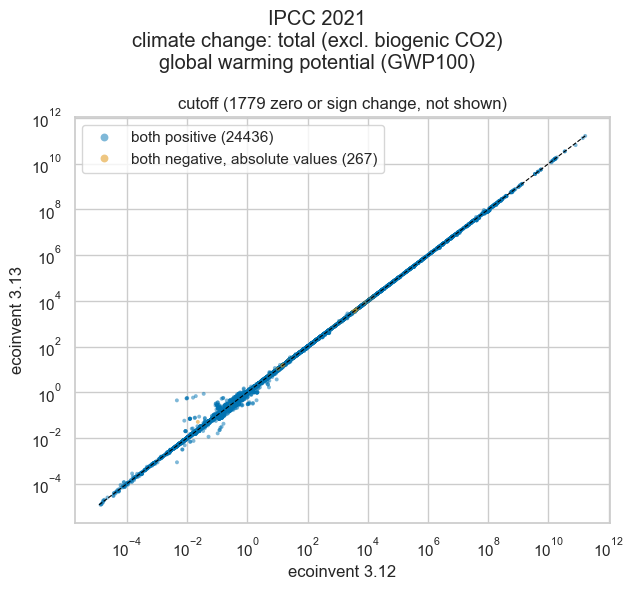

In [14]:
def save_figure(fig, name):
    fig.savefig(OUTPUT_DIR / "figures" / f"{name}.png", dpi=150)
    if SAVE_FIGURES_TO_CWD:
        fig.savefig(Path.cwd() / f"ecoinvent-{VERSION}-{name}.png", dpi=150)


def plot_grid(n):
    ncols = min(n, 2)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 6 * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


fig, axes = plot_grid(len(comparisons))
for ax, (system_model, df) in zip(axes, comparisons.items()):
    positive = (df["new"] > 0) & (df["old"] > 0)
    negative = (df["new"] < 0) & (df["old"] < 0)
    plot_data = pd.DataFrame(
        {
            "old": df.loc[positive | negative, "old"].abs(),
            "new": df.loc[positive | negative, "new"].abs(),
            "scores": np.where(
                positive[positive | negative],
                f"both positive ({positive.sum()})",
                f"both negative, absolute values ({negative.sum()})",
            ),
        }
    )
    sns.scatterplot(data=plot_data, x="old", y="new", hue="scores", s=8, alpha=0.5, linewidth=0, ax=ax)
    lo, hi = plot_data[["old", "new"]].min().min(), plot_data[["old", "new"]].max().max()
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=0.8, linestyle="--")
    ax.set(xscale="log", yscale="log", xlabel=f"ecoinvent {PREVIOUS_VERSION}", ylabel=f"ecoinvent {VERSION}")
    other = len(df) - positive.sum() - negative.sum()
    ax.set_title(f"{system_model} ({other} zero or sign change, not shown)")
    sns.move_legend(ax, "upper left", title=None, markerscale=2)
fig.suptitle("\n".join(COMPARISON_METHOD))
fig.tight_layout()
save_figure(fig, "previous-version-scatter")

Distribution of the ratio of new to old scores (same sign, non-zero).

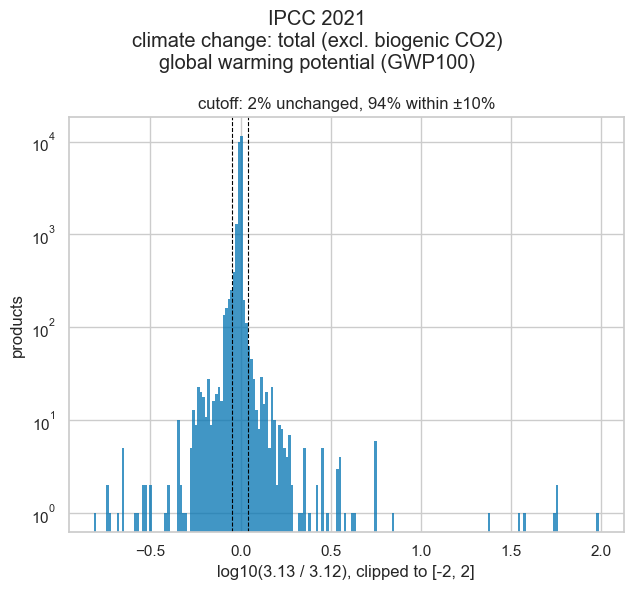

In [15]:
fig, axes = plot_grid(len(comparisons))
for ax, (system_model, df) in zip(axes, comparisons.items()):
    same_sign = (df["new"] * df["old"]) > 0
    log_ratio = np.log10(df.loc[same_sign, "ratio"])
    sns.histplot(log_ratio.clip(-2, 2), bins=200, edgecolor="none", ax=ax)
    # Log scale after plotting; `log_scale=(False, True)` doesn't draw bars starting at zero
    ax.set_yscale("log")
    for x in (np.log10(0.9), np.log10(1.1)):
        ax.axvline(x, color="black", linewidth=0.8, linestyle="--")
    ax.set(xlabel=f"log10({VERSION} / {PREVIOUS_VERSION}), clipped to [-2, 2]", ylabel="products")
    within = (np.abs(log_ratio) <= np.log10(1.1)).mean()
    unchanged = (np.abs(log_ratio) < 1e-9).mean()
    ax.set_title(f"{system_model}: {unchanged:.0%} unchanged, {within:.0%} within ±10%")
fig.suptitle("\n".join(COMPARISON_METHOD))
fig.tight_layout()
save_figure(fig, "previous-version-ratio")

In [16]:
def largest_changes(df, n=25):
    df = df[(df["new"] * df["old"]) > 0].copy()
    df["abs log10 ratio"] = np.abs(np.log10(df["ratio"]))
    return df.sort_values("abs log10 ratio", ascending=False).head(n)


SCORE_COLUMNS = ["old", "new"] if SHOW_SCORES else []

for system_model, df in comparisons.items():
    df[MATCH + SCORE_COLUMNS + ["ratio"]].to_csv(OUTPUT_DIR / "tables" / f"previous-version-{system_model}.csv", index=False)
    sign_changes = df[(df["new"] * df["old"]) < 0]
    display(Markdown(f"**{system_model}**: largest changes; {len(sign_changes)} products changed sign"))
    display(largest_changes(df)[MATCH + SCORE_COLUMNS + ["ratio"]])

**cutoff**: largest changes; 1 products changed sign

,name,reference product,location,unit,ratio
16156,"electricity, high voltage, production mix","electricity, high voltage",CG,kilowatt hour,96.598935
1034,"electricity, high voltage, import from CG","electricity, high voltage",CD,kilowatt hour,56.061776
17349,"market for electricity, high voltage","electricity, high voltage",CG,kilowatt hour,56.061776
14515,electricity voltage transformation from high to medium voltage,"electricity, medium voltage",CG,kilowatt hour,55.718576
25484,"market for electricity, medium voltage","electricity, medium voltage",CG,kilowatt hour,37.018118
9678,electricity voltage transformation from medium to low voltage,"electricity, low voltage",CG,kilowatt hour,35.034432
20427,"market for electricity, low voltage","electricity, low voltage",CG,kilowatt hour,24.051705
19631,"electricity, high voltage, production mix","electricity, high voltage",CR,kilowatt hour,7.083239
12176,"electricity, high voltage, production mix","electricity, high voltage",CM,kilowatt hour,0.153664
7356,"market for electricity, high voltage","electricity, high voltage",CR,kilowatt hour,5.610721


## 4. Comparison with official ecoinvent scores

ecoinvent publishes cumulative LCIA scores for every product as an Excel file per system model. Rows are labelled `ActivityUUID_ProductUUID`, and columns with the same Method, Category and Indicator labels as the Brightway method names.

Both are per reference product amount (see above). A score **disagrees** if the relative difference `|ours - official| / max(|ours|, |official|)` is larger than `OFFICIAL_RTOL`, and the larger of the two scores isn't negligible, i.e. at least 1e-9 of the largest absolute official score for that impact category. Smaller differences are numerical noise around zero. Disagreements are reported as `(official - ours) / |ours|`; set `SHOW_SCORES = True` to also see both scores.

Reading the Excel files takes a few minutes each; the parsed tables are cached in `OUTPUT_DIR/official`.

In [17]:
def read_official_scores(version, system_model):
    fp = OUTPUT_DIR / "official" / f"ecoinvent-{version}-{system_model}.parquet"
    if fp.exists():
        return pd.read_parquet(fp)

    directory = release.get_release(version, system_model, ReleaseType.cumulative_lcia)
    (excel,) = [f for f in Path(directory).iterdir() if f.suffix == ".xlsx" and not f.name.startswith("~")]
    try:
        import python_calamine  # noqa: F401

        raw = pd.read_excel(excel, sheet_name="LCIA", header=None, engine="calamine")
        rows = raw.itertuples(index=False, name=None)
    except ImportError:
        from openpyxl import load_workbook

        rows = load_workbook(excel, read_only=True)["LCIA"].iter_rows(values_only=True)

    rows = iter(rows)
    method_row, category_row, indicator_row, unit_row = (next(rows) for _ in range(4))
    first = method_row.index("Method") + 1
    columns = ["|".join(str(x).strip() for x in triple) for triple in zip(method_row[first:], category_row[first:], indicator_row[first:])]
    keys, amounts, values = [], [], []
    for row in rows:
        if row[0] is None:
            continue
        keys.append(row[0])
        amounts.append(row[first - 1])
        values.append(row[first:])
    df = pd.DataFrame(np.array(values, dtype=float), columns=columns)
    df.insert(0, "key", keys)
    df.insert(1, "reference product amount", np.array(amounts, dtype=float))
    df.to_parquet(fp)
    return df


official = {system_model: read_official_scores(VERSION, system_model) for system_model in SYSTEM_MODELS}
{k: v.shape for k, v in official.items()}

{'cutoff': (27400, 616)}

In [18]:
def compare_official(ours, theirs):
    ours = ours.set_index("key")
    theirs = theirs.set_index("key")
    official_amount = theirs.pop("reference product amount")
    if theirs.columns.duplicated().any():
        print("Duplicated official columns:", list(theirs.columns[theirs.columns.duplicated()]))
        theirs = theirs.loc[:, ~theirs.columns.duplicated()]
    our_methods = [c for c in ours.columns if c not in LABELS]
    methods = [c for c in our_methods if c in theirs.columns]
    products = ours.index.intersection(theirs.index)
    amount_mismatch = products[ours.loc[products, "production amount"].to_numpy() != official_amount.loc[products].to_numpy()]
    if len(amount_mismatch):
        print(f"{len(amount_mismatch)} products have a different reference product amount in the official file:", list(amount_mismatch[:10]))
    unmatched = {
        "methods only in Brightway": sorted(set(our_methods).difference(theirs.columns)),
        "methods only in official": sorted(set(theirs.columns).difference(our_methods)),
        "products only in Brightway": sorted(set(ours.index).difference(theirs.index)),
        "products only in official": sorted(set(theirs.index).difference(ours.index)),
    }

    a = ours.loc[products, methods].to_numpy()
    b = theirs.loc[products, methods].to_numpy()
    scale = np.maximum(np.abs(a), np.abs(b))
    relative = np.divide(np.abs(a - b), scale, out=np.zeros_like(scale), where=scale > 0)
    negligible = scale < 1e-9 * np.nanmax(np.abs(b), axis=0, keepdims=True)
    disagree = (relative > OFFICIAL_RTOL) & ~negligible

    per_method = pd.DataFrame(
        {
            "method": methods,
            "disagreements": disagree.sum(axis=0),
            "max relative difference": np.where(negligible, 0, relative).max(axis=0),
            "median relative difference": np.median(relative, axis=0),
            "official all zero": (b == 0).all(axis=0),
            "ours all zero": (a == 0).all(axis=0),
        }
    ).sort_values(["disagreements", "max relative difference"], ascending=False)

    rows, cols = np.nonzero(disagree)
    labels = ours.loc[products, ["name", "reference product", "location", "unit"]]
    ours_values, official_values = a[rows, cols], b[rows, cols]
    details = pd.DataFrame(
        {
            "method": np.array(methods)[cols],
            "key": products[rows],
            "(official - ours) / |ours|": (official_values - ours_values) / np.abs(ours_values),
            "relative difference": relative[rows, cols],
        }
    )
    if SHOW_SCORES:
        details["ours"], details["official"] = ours_values, official_values
    details = details.join(labels, on="key")
    return {
        "unmatched": unmatched,
        "per method": per_method,
        "details": details.sort_values("relative difference", ascending=False),
        "relative": relative[~negligible & (scale > 0)],
        "n": a.size,
    }


official_comparisons = {}
for system_model in SYSTEM_MODELS:
    result = compare_official(scores[(VERSION, system_model)], official[system_model])
    official_comparisons[system_model] = result
    result["per method"].to_csv(OUTPUT_DIR / "tables" / f"official-{system_model}-per-method.csv", index=False)
    result["details"].drop(columns="relative difference").to_csv(OUTPUT_DIR / "tables" / f"official-{system_model}-disagreements.csv", index=False)
    print(
        f"{system_model}: {result['n']} scores compared, {len(result['details'])} disagreements "
        f"in {(result['per method']['disagreements'] > 0).sum()} impact categories; unmatched: "
        + ", ".join(f"{k} {len(v)}" for k, v in result["unmatched"].items())
    )

cutoff: 16823600 scores compared, 2 disagreements in 2 impact categories; unmatched: methods only in Brightway 41, methods only in official 0, products only in Brightway 0, products only in official 0


Distribution of relative differences, excluding negligible scores and scores which are both zero.

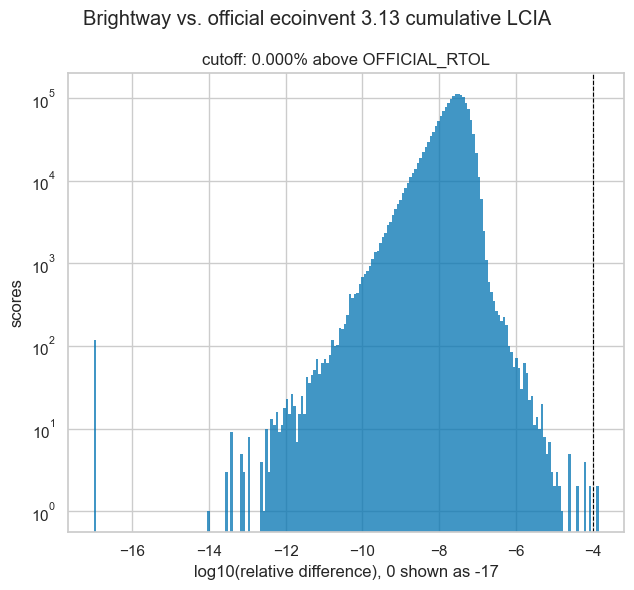

In [19]:
fig, axes = plot_grid(len(official_comparisons))
for ax, (system_model, result) in zip(axes, official_comparisons.items()):
    relative = result["relative"]
    sns.histplot(np.log10(np.maximum(relative, 1e-17)), bins=200, edgecolor="none", ax=ax)
    # Log scale after plotting; `log_scale=(False, True)` doesn't draw bars starting at zero
    ax.set_yscale("log")
    ax.axvline(np.log10(OFFICIAL_RTOL), color="black", linewidth=0.8, linestyle="--")
    ax.set(xlabel="log10(relative difference), 0 shown as -17", ylabel="scores")
    ax.set_title(f"{system_model}: {(relative > OFFICIAL_RTOL).mean():.3%} above OFFICIAL_RTOL")
fig.suptitle(f"Brightway vs. official ecoinvent {VERSION} cumulative LCIA")
fig.tight_layout()
save_figure(fig, "official-relative-differences")

In [20]:
for system_model, result in official_comparisons.items():
    display(Markdown(f"### {system_model}"))
    for label, items in result["unmatched"].items():
        if items:
            lines = [f"* {str(item).replace('|', ' | ')}" for item in items[:50]]
            if len(items) > 50:
                lines.append(f"* ... and {len(items) - 50} more")
            display(Markdown(f"**{label}** ({len(items)}):\n\n" + "\n".join(lines)))
    display(Markdown("**Impact categories with disagreements**"))
    display(result["per method"][result["per method"]["disagreements"] > 0].head(30))
    display(Markdown("**Largest disagreements**"))
    display(result["details"].drop(columns="relative difference").head(30))

### cutoff

**methods only in Brightway** (41):

* EN15804+A2 - Additional impact categories and indicators | ecotoxicity: freshwater (EF v3.0) | comparative toxic unit for ecosystems (CTUe)
* EN15804+A2 - Additional impact categories and indicators | ecotoxicity: freshwater (EF v3.1) | comparative toxic unit for ecosystems (CTUe)
* EN15804+A2 - Additional impact categories and indicators | human toxicity: carcinogenic | comparative toxic unit for human (CTUh)
* EN15804+A2 - Additional impact categories and indicators | human toxicity: non-carcinogenic (EF v3.0) | comparative toxic unit for human (CTUh)
* EN15804+A2 - Additional impact categories and indicators | human toxicity: non-carcinogenic (EF v3.1) | comparative toxic unit for human (CTUh)
* EN15804+A2 - Additional impact categories and indicators | ionising radiation: human health | human exposure efficiency relative to u235
* EN15804+A2 - Additional impact categories and indicators | land use | soil quality index
* EN15804+A2 - Additional impact categories and indicators | particulate matter formation | impact on human health
* EN15804+A2 - Core impact categories and indicators | acidification | accumulated exceedance (AE)
* EN15804+A2 - Core impact categories and indicators | climate change: biogenic (EF v3.0 - IPCC 2013) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: biogenic (EF v3.1 - IPCC 2021) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: fossil (EF v3.0 - IPCC 2013) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: fossil (EF v3.1 - IPCC 2021) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: land use and land use change (EF v3.0 - IPCC 2013) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: land use and land use change (EF v3.1 - IPCC 2021) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: total (EF v3.0 - IPCC 2013) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | climate change: total (EF v3.1 - IPCC 2021) | global warming potential (GWP100)
* EN15804+A2 - Core impact categories and indicators | energy resources: non-renewable | abiotic depletion potential (ADP): fossil fuels
* EN15804+A2 - Core impact categories and indicators | eutrophication: freshwater | fraction of nutrients reaching freshwater end compartment (P)
* EN15804+A2 - Core impact categories and indicators | eutrophication: marine | fraction of nutrients reaching marine end compartment (N)
* EN15804+A2 - Core impact categories and indicators | eutrophication: terrestrial | accumulated exceedance (AE)
* EN15804+A2 - Core impact categories and indicators | material resources: metals/minerals | abiotic depletion potential (ADP): elements (ultimate reserves)
* EN15804+A2 - Core impact categories and indicators | ozone depletion | ozone depletion potential (ODP)
* EN15804+A2 - Core impact categories and indicators | photochemical oxidant formation: human health | tropospheric ozone concentration increase
* EN15804+A2 - Core impact categories and indicators | water use | user deprivation potential (deprivation-weighted water consumption)
* EN15804+A2 - Indicators describing output flows | components for re-use | CRU
* EN15804+A2 - Indicators describing output flows | exported energy - electricity | EEE
* EN15804+A2 - Indicators describing output flows | exported energy - heat | EET
* EN15804+A2 - Indicators describing output flows | exported energy | EE
* EN15804+A2 - Indicators describing output flows | materials for energy recovery | MER
* EN15804+A2 - Indicators describing output flows | materials for recycling | MFR
* EN15804+A2 - Indicators describing resource use | net use of fresh water | FW
* EN15804+A2 - Indicators describing resource use | total use of non-renewable primary energy resources (primary energy and primary energy resources used as raw materials) | PENRT
* EN15804+A2 - Indicators describing resource use | total use of renewable primary energy resources (primary energy and primary energy resources used as raw materials) | PERT
* EN15804+A2 - Indicators describing resource use | use of non-renewable secondary fuels | NRSF
* EN15804+A2 - Indicators describing resource use | use of renewable secondary fuels | RSF
* EN15804+A2 - Indicators describing resource use | use of secondary material | SM
* EN15804+A2 - Indicators describing waste categories | hazardous waste disposed | HWD
* EN15804+A2 - Indicators describing waste categories | high-level radioactive waste disposed | HLRW
* EN15804+A2 - Indicators describing waste categories | intermediate and low-level radioactive waste disposed | ILLRW
* EN15804+A2 - Indicators describing waste categories | non-hazardous waste disposed | NHWD

**Impact categories with disagreements**

,method,disagreements,max relative difference,median relative difference,official all zero,ours all zero
267,IPCC 2021 (incl. biogenic CO2)|climate change: biogenic (incl. CO2)|global w...,1,0.000145,7.395076e-08,False,False
272,IPCC 2021 (incl. biogenic CO2) no LT|climate change: biogenic (incl. CO2) no...,1,0.000145,7.395076e-08,False,False


**Largest disagreements**

,method,key,(official - ours) / |ours|,name,reference product,location,unit
0,IPCC 2021 (incl. biogenic CO2)|climate change: biogenic (incl. CO2)|global w...,a2b48417-37c9-5f90-8f71-970c7144d92e_9ffca1fd-6373-4acc-ad91-7d9380fa8058,-0.000145,"train production, passenger, high speed","train, passenger, high speed",RoW,unit
1,IPCC 2021 (incl. biogenic CO2) no LT|climate change: biogenic (incl. CO2) no...,a2b48417-37c9-5f90-8f71-970c7144d92e_9ffca1fd-6373-4acc-ad91-7d9380fa8058,-0.000145,"train production, passenger, high speed","train, passenger, high speed",RoW,unit
